# **Lab 3: Filters I**
### All-Pass and Add-Drop Ring Resonators
***

**Name**: Andrés Sanchez-Toril
***

#### **Section 1**:  All-Pass Ring Resonator
In general a ring resonator consists of a looped optical waveguide and a coupling mechanism to access the loop. When the waves in the loop build up a round trip phase shift that equals an integer times $2\pi$, the waves interfere constructively and the cavity is in resonance.

The basic configuration consists of unidirectional coupling between a ring resonator with radius $r$ and a waveguide.

<figure> 
    <center>
        <img src="Images/Images/APF.png" style="width:40%">
        <figcaption align = "center"> <i> <b> Fig. 1. </b> Model of a single ring resonator with one waveguide </i> </figcaption>
    </center>
</figure>

Defining that a single unidirectional mode of the resonator is excited, the coupling is lossless, single polarization is considered, none of the waveguide segments and coupler elements couple waves of different polarization, the various kinds of losses occurring along the propagation of light in the ring resonator filter are incorporated in the attenuation constant, the interaction can be described by the matrix relation:

\begin{equation*}
\begin{pmatrix}
E_{t1} \\
E_{t2}
\end{pmatrix}
= 
\begin{pmatrix}
t & \kappa \\
-\kappa^* & t*
\end{pmatrix}
\begin{pmatrix}
E_{i1} \\
E_{i2}
\end{pmatrix}
\tag{1}
\end{equation*}

The complex mode amplitudes $E$ are normalized, so that their squared magnitude corresponds to the modal power. The coupler parameters $t$ and $\kappa$ depend
on the specific coupling mechanism used. The $^*$ denotes the conjugated complex value of $t$ and $\kappa$, respectively.

The matrix is symmetric because the networks under consideration are reciprocal. Therefore

\begin{equation*}
|\kappa^2|+|t^2|=1
\tag{2}
\end{equation*}

In order to further simplify the model, $E_{i1}$ is chosen to be equal to 1. Then the round trip in the ring is given by

\begin{equation*}
E_{i2} = \alpha e^{j\tau} E_{t2}
\tag{3}
\end{equation*}

where $\alpha$ is the loss coefficient of the ring (zero loss: $\alpha=1$) and $\tau=\omega L / c$, $L$ being the circumference of the ring which is given by $L = 2\pi r$, $r$ being the radius of the ring measured from the center of the ring to the center of the waveguide, $c$ the phase velocity of the ring mode ($c= c_0 / n_{\text{eff}}$) and the fixed angular frequency $\omega = k c_0$, $c_0$ refers to the vacuum speed of light. The vacuum wavenumber $k$ is related to the wavelength $\lambda$ through: $k=2\pi / \lambda$. Using the vacuum wavenumber, the effective refractive index neff can be introduced easily into the ring coupling relations by

\begin{equation*}
\beta = k n_{\text{eff}} = \dfrac{2\pi n_{\text{eff}}}{\lambda}
\tag{4}
\end{equation*}

where $\beta$ is the propagation constant. This leads to 

\begin{equation*}
\tau = \dfrac{\omega L}{c} = \dfrac{k c_0 L}{c} = k n_{\text{eff}} 2\pi r = 4\pi^2 n_{\text{eff}} \dfrac{r}{\lambda}
\tag{5}
\end{equation*}

From 1 and 3 we obtain

\begin{equation*}
E_{t1} = \dfrac{-\alpha + te^{-j\tau}}{-\alpha t^* + te^{-j\tau}}
\tag{6}
\end{equation*}

\begin{equation*}
E_{i2} = \dfrac{-\alpha \kappa^*}{-\alpha t^* + te^{-j\tau}}
\tag{7}
\end{equation*}

\begin{equation*}
E_{t2} = \dfrac{-\kappa^*}{1 -\alpha t^*e^{j\tau}}
\tag{8}
\end{equation*}



First, we import Python libraries we need:

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

Effective refractive index $n_{\text{eff}}$ is dependent with wavelength. In next section we provide values from a simulation of a SOI (Silicon on Insulator) waveguide and we do a fitting for wavelenghts from 1500 to 1600 nm. We will use this for the next simulations of the ring resonators.

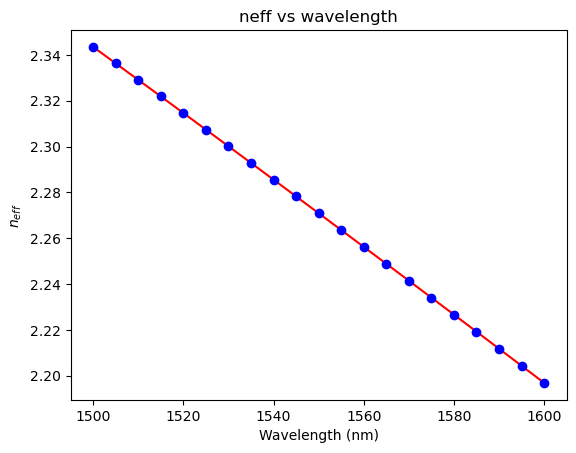

In [4]:
# Wavelength points
wvl_data = np.linspace(1500e-9, 1600e-9, 21)
# PhoeniX Field Designer simulated data for effective refractive index (TE0 mode) for a 450x220 silicon on insulator waveguide
neff_data = [2.34346, 2.33627, 2.32907, 2.32185, 2.31461, 2.30737, 2.3001, 2.29282, 2.28553, 2.27822, 2.2709, 
        2.26356, 2.2562, 2.24883, 2.24145, 2.23405, 2.22664, 2.21921, 2.21177, 2.20431, 2.19683]

# Fit the effective index to a polynomial function
p = np.poly1d(np.polyfit(wvl_data, neff_data, 6))
# Final wavelength vectir with 200 points
wvl = np.linspace(1500e-9, 1600e-9, 200)
#  Neff from the fitting function with new wavelength
neff = p(wvl)

# Plot of the neff vs. wavelegth
plt.figure()
plt.title("neff vs wavelength")
plt.plot(wvl*1e9, neff, 'r')
plt.plot(wvl_data*1e9, neff_data, 'ob')
plt.xlabel('Wavelength (nm)')
plt.ylabel('$n_{eff}$')
plt.show()

Now, we are going to see how is the response of the ring resonator, using equation (6). First, we define the parameters:

In [5]:
# Parameters
n = 5000 # Number of points
wvl = np.linspace(1549.5e-9, 1550.5e-9, n)
neff = p(wvl)
r = 0.3e-3 # Radius of the ring
L = 2*np.pi*r # Round-trip length of the ring 

And then, we calcule the loss coefficient $\alpha$ for an specific waveguide losses in dB/cm:

In [6]:
# Losses
loss_wg = 1 # Waveguide losses (dB/cm)
loss_dB = loss_wg*L*1e2 # Total losses of the ring in dB
loss_Np = loss_dB/(20*np.log10(np.exp(1))) # Total losses of the ring in Nepers (Np)
alpha = np.exp(-loss_Np) # Loss coefficient
print('Total losses of the ring: ' + str(loss_dB) + ' dB')
print('Loss Coefficient α = ' + str(alpha))

Total losses of the ring: 0.18849555921538758 dB
Loss Coefficient α = 0.9785324269595155


Finally, we choose a coupling coefficient $t$ or $\kappa$ and plot the output response:

[Text(0.5, 0, 'Wavelength (nm)'), Text(0, 0.5, 'Optical Response (dB)')]

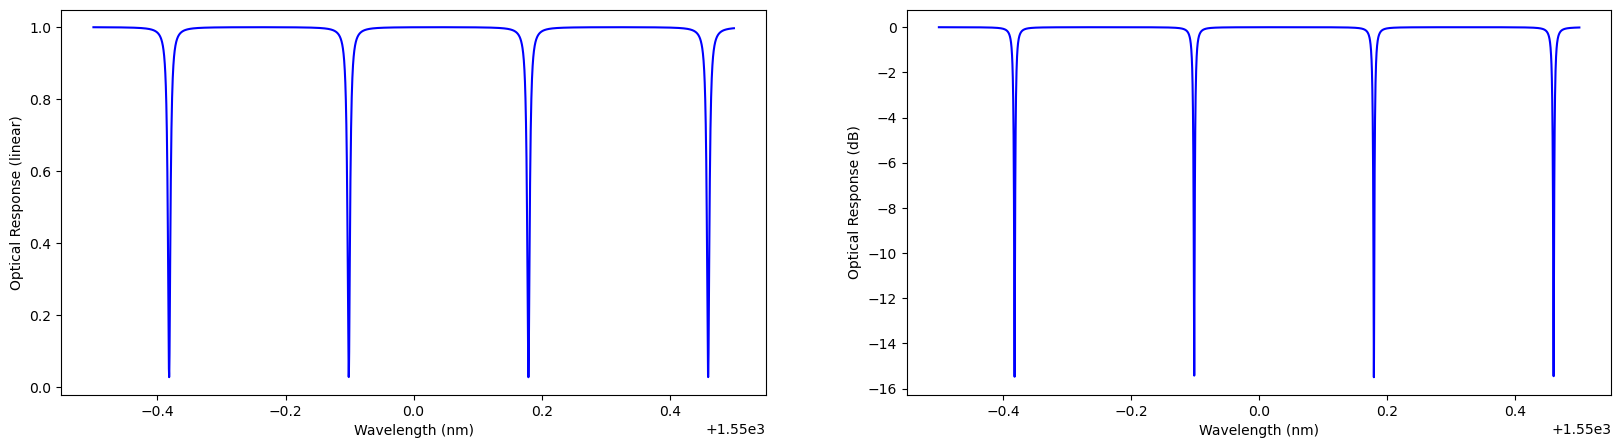

In [7]:
# Coupling coefficients
t = 0.97 # You can change this parameter and see the resulting response
k = np.sqrt(1-t**2)

# Angular phase
tau = (4 * np.pi**2 * neff * r) / wvl

# Output field
Et1 = (-alpha + t*np.exp(-1j*tau)) / (-alpha*np.conjugate(t) + np.exp(-1j*tau)) 
Pt1 = abs(Et1)**2 # Transmission power in the output waveguide

# Plot figures
fig, axs = plt.subplots(1,2,figsize=(20, 5))
# Linear
axs[0].plot(wvl*1e9, Pt1, 'b')
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
# Logarithmic
axs[1].plot(wvl*1e9, 10*np.log10(Pt1), 'b')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')

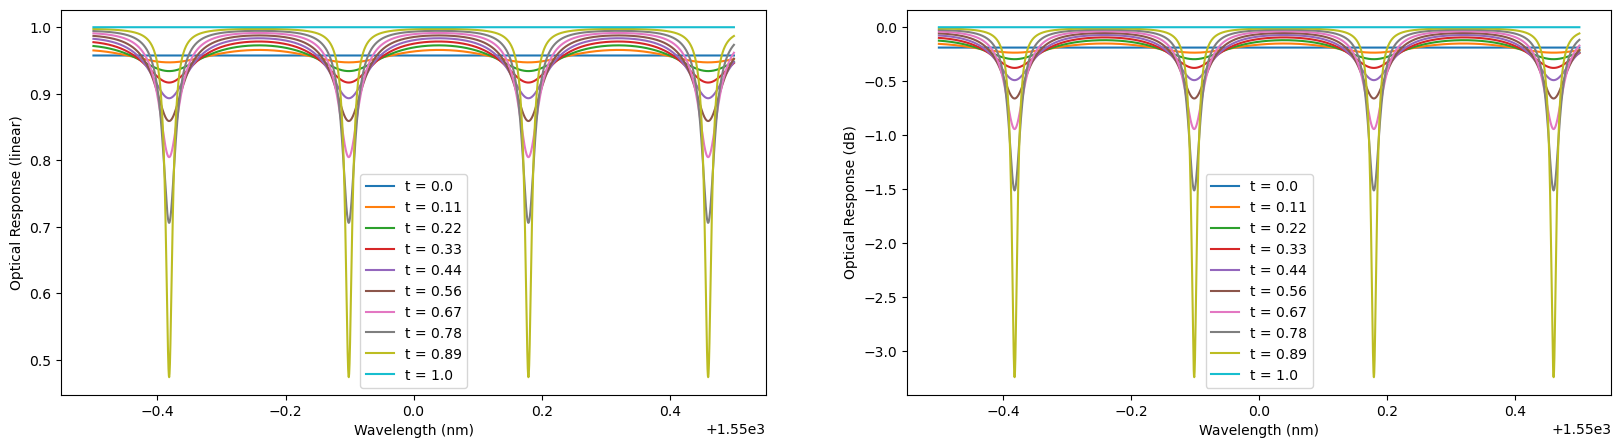

In [8]:
t = np.linspace(0,1,10)

fig, axs = plt.subplots(1,2,figsize=(20, 5))
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')

for i in range(len(t)):
    # Output field
    Et1 = (-alpha + t[i]*np.exp(-1j*tau)) / (-alpha*np.conjugate(t[i]) + np.exp(-1j*tau)) 
    Pt1 = abs(Et1)**2 # Transmission power in the output waveguide

    # Plot figures
    # Linear
    axs[0].plot(wvl*1e9, Pt1, label='t = ' + str(round(t[i],2)))
    # Logarithmic
    axs[1].plot(wvl*1e9, 10*np.log10(Pt1), label='t = ' + str(round(t[i],2)))

axs[0].legend()
axs[1].legend()

***
#### **Section 2:** All-Pass Ring Resonator using a Tunable MZI

<figure> 
    <center>
        <img src="Images/Images/ring_puc.png" style="width:40%">
        <figcaption align = "center"> <i> <b> Fig. 2. </b> Model of a single all-pass ring resonator implemented with a tunable MZI </i> </figcaption>
    </center>
</figure>

Change the matrix of equation (1) with the matrix corresponding to an MZI and program its response as in Section 1 for different coupling values. In this case $\kappa = \cos \theta$ and $t = \sin \theta$

\begin{equation*}
S = -je^{j\Delta} \alpha_{\text{MZI}}
\begin{pmatrix}
\sin\theta & \cos\theta \\
\cos\theta & -\sin\theta
\end{pmatrix}
\tag{9}
\end{equation*}

Where

\begin{equation*}
\Delta = 2\varphi_0 - \dfrac{\phi_1+\phi_2}{2}
\tag{10}
\end{equation*}

\begin{equation*}
\theta = \dfrac{\phi_2-\phi_1}{2}
\tag{11}
\end{equation*}

\begin{equation*}
\alpha \text{(dB)} = \alpha_{\text{ring}} \text{(dB)} + \alpha_{\text{MZI}} \text{(dB)}
\tag{12}
\end{equation*}

The parameter $\varphi_0$ is the phase introduced by the MMI. Is a fixed parameter that depends on its structure, we show the way to obtain it:

In [ ]:
# MMI phase calculation

# Parameters
n = 5000 # Number of points
wvl = np.linspace(1549.5e-9, 1550.5e-9, n)
neff = p(wvl)

k0 = 2*np.pi/wvl
beta0 = k0*neff

Ln = 24.5e-6 # Length for a 2x2 MMI
phi0 = -beta0*Ln - 3*np.pi/4

**Exercise 1**: Program and plot the response of the ring of Fig. 2 for phase shifter values $\phi_1 = 0.8\pi$ and $\phi_2 = 0.1\pi$ in the code box below:

In [ ]:
# Ring Losses
loss_wg = 1 # Waveguide losses (dB/cm)
loss_ring_dB = loss_wg*L*1e2 # Total losses of the ring in dB
loss_mzi_dB = .5
loss_Np = loss_ring_dB/(20*np.log10(np.exp(1))) # Total losses of the ring in Nepers (Np)
loss_Np_mzi = loss_mzi_dB/(20*np.log10(np.exp(1))) # Total losses of the mzi in Nepers (Np)
alpha = loss_Np + loss_Np_mzi # Suma de los alphas del ring y del MZI
alpha = np.exp(-alpha)


phi1 = 0.8 * np.pi
phi2 = 0.1 * np.pi

theta = (phi2 - phi1)/2
delta = 2 * phi0 - (phi1 + phi2)/2

print('Total losses of the ring: ' + str(loss_ring_dB + loss_mzi_dB) + ' dB')
print('Loss Coefficient α = ' + str(alpha))

Total losses of the ring: 0.6884955592153876 dB
Loss Coefficient α = 0.9237941804695915


[Text(0.5, 0, 'Wavelength (nm)'), Text(0, 0.5, 'Optical Response (dB)')]

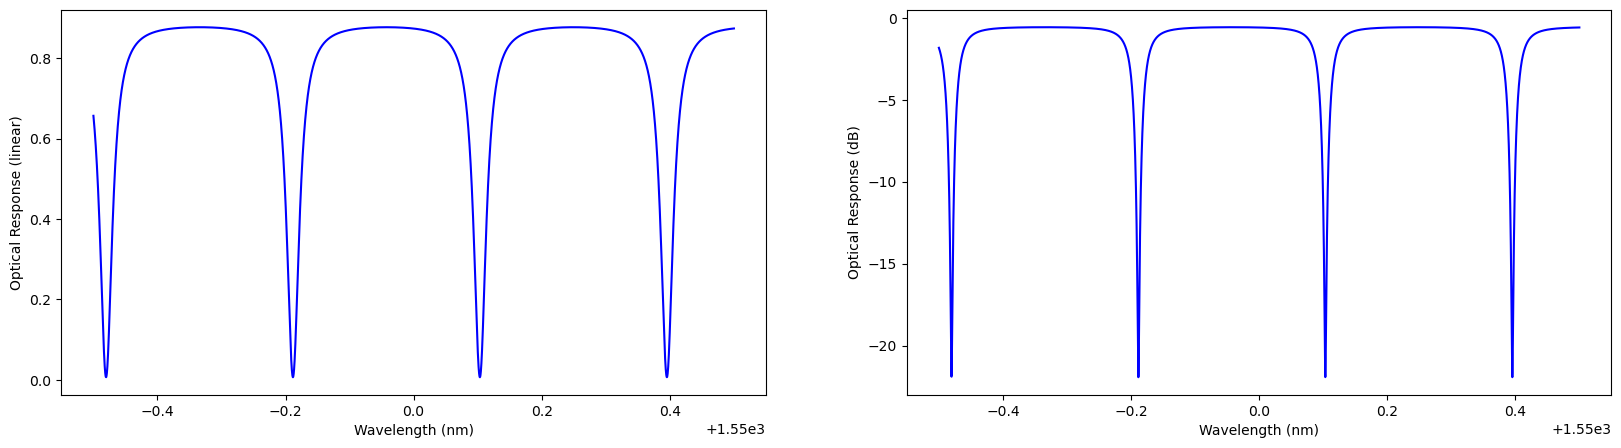

In [ ]:
# Coupling coefficients
k = np.cos(theta) # You can change this parameter and see the resulting response
t = np.sin(theta)

# Angular phase
tau = (4 * np.pi**2 * neff * r) / wvl

# Output field. Las ecuaciones las sacamos de despejar de la multiplicación de S por la entrada
Et2 = (-1j * np.exp(1j *delta) * np.exp(-loss_Np_mzi) * k)/(1 -1j * np.exp(1j *delta) * np.exp(-loss_Np_mzi) * t * alpha * np.exp(1j * (tau + phi0)))
Ei2 = alpha * np.exp(1j*(tau + phi0)) * Et2
Et1 = -1j * np.exp(1j * delta) * np.exp(-loss_Np_mzi) * (t + k * Ei2)
Pt1 = abs(Et1)**2 # Transmission power in the output waveguide

# Plot figures
fig, axs = plt.subplots(1,2,figsize=(20, 5))
# Linear
axs[0].plot(wvl*1e9, Pt1, 'b')
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
# Logarithmic
axs[1].plot(wvl*1e9, 10*np.log10(Pt1), 'b')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')

**Exercise 2**: Plot the same response of the Exercise 1 for different values of coupling $t$ from 0 to 1 (in the same plot figure).

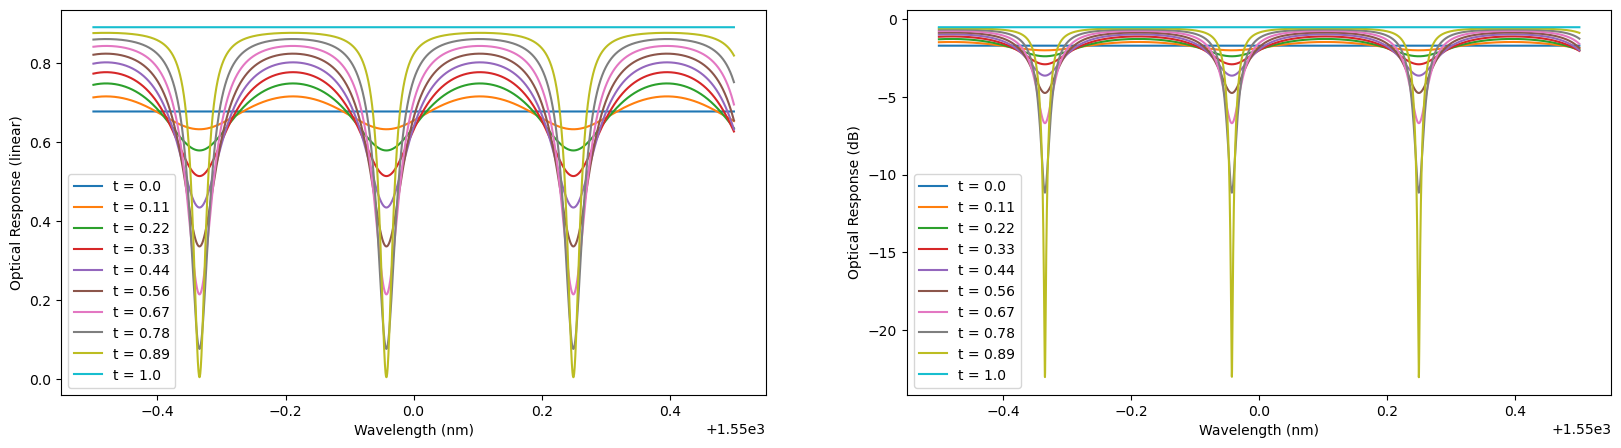

In [96]:
t = np.linspace(0,1,10)
k = np.sqrt(1-t**2)

fig, axs = plt.subplots(1,2,figsize=(20, 5))
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')

for i in range(len(t)):
    # Output field
    Et2 = (-1j * np.exp(1j *delta) * np.exp(-loss_Np_mzi) * k[i])/(1 -1j * np.exp(1j *delta) * np.exp(-loss_Np_mzi) * t[i] * alpha * np.exp(1j * (tau + phi0)))
    Ei2 = alpha * np.exp(1j*(tau + phi0)) * Et2
    Et1 = -1j * np.exp(1j * delta) * np.exp(-loss_Np_mzi) * (t[i] + k[i] * Ei2)
    Pt1 = abs(Et1)**2 # Transmission power in the output waveguide

    # Plot figures
    # Linear
    axs[0].plot(wvl*1e9, Pt1, label='t = ' + str(round(t[i],2)))
    # Logarithmic
    axs[1].plot(wvl*1e9, 10*np.log10(Pt1), label='t = ' + str(round(t[i],2)))

axs[0].legend()
axs[1].legend()

***
#### **Section 4:** Add-Drop Ring Resonator

The next configuration which is discussed is the basic ring resonator add–drop configuration, consisting of one input, one output waveguide and the ring resonator. The four ports of the ring resonator are referred to in the following as input port, throughput port, drop port and add port.


<figure> 
    <center>
        <img src="Images/Images/add-drop.png" style="width:35%">
        <figcaption align = "center"> <i> <b> Fig. 3. </b> Model of a basic add–drop single ring resonator filter </i> </figcaption>
    </center>
</figure>

The throughput mode amplitude in the first waveguide is given by

\begin{equation*}
E_{t1} = \dfrac{t_1 - t_2^* \alpha e^{j\tau}}{1- t_1^* t_2^* \alpha  e^{j\tau}}
\tag{13}
\end{equation*}

In this calculation, $\alpha_{1/2}$ and $\tau_{1/2}$ are used which are the half round trip loss and phase, respectively. It is $\alpha = \alpha_{1/2}^2$ and $\tau = 2\tau_{1/2}$.

Now, the mode amplitude in the ring has to pass the second coupler as can be seen from the schematic to become the new dropped mode amplitude $E_{t2}$. The dropped mode amplitude in the second waveguide is then given by:

\begin{equation*}
E_{t2} = \dfrac{-\kappa_1^* \kappa_2 \alpha_{1/2} e^{j\tau_{1/2}}}{1- t_1^* t_2^* \alpha  e^{j\tau}} = \dfrac{-\kappa_1^* \kappa_2 \sqrt{\alpha} e^{j(\tau /2)}}{1- t_1^* t_2^* \alpha  e^{j\tau}}
\end{equation*}


Total losses of the ring: 0.18849555921538758 dB
Loss Coefficient α = 0.9785324269595155


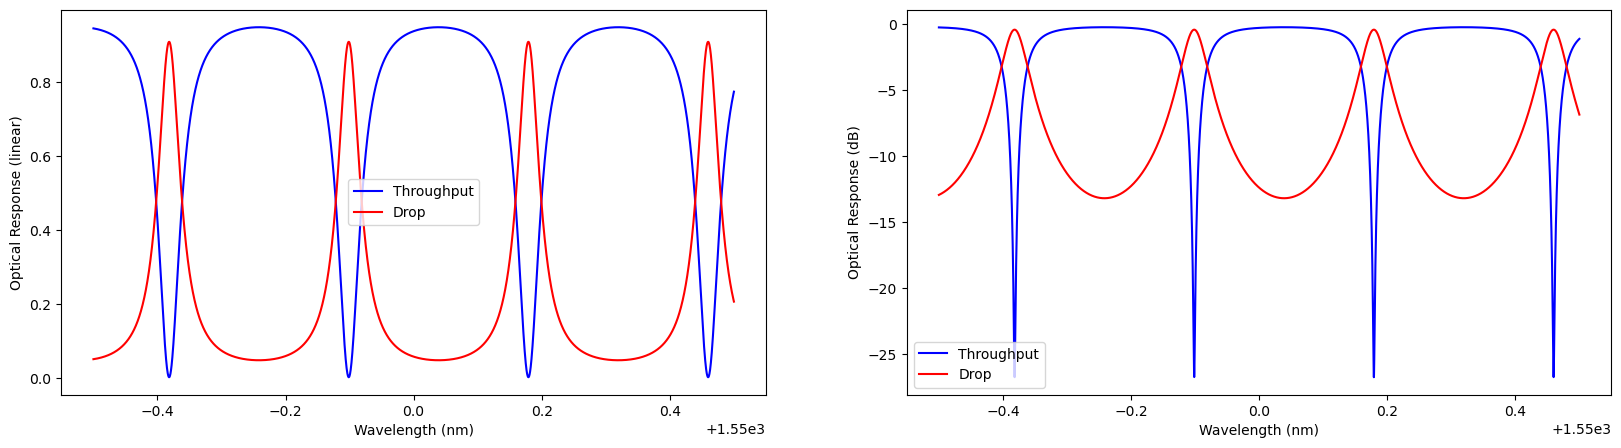

In [82]:
# Parameters
n = 5000 # Number of points
wvl = np.linspace(1549.5e-9, 1550.5e-9, n)
neff = p(wvl)
r = 0.3e-3 # Radius of the ring
L = 2*np.pi*r # Round-trip length of the ring 

# Losses
loss_wg = 1 # Waveguide losses (dB/cm)
loss_dB = loss_wg*L*1e2 # Total losses of the ring in dB
loss_Np = loss_dB/(20*np.log10(np.exp(1))) # Total losses of the ring in Nepers (Np)
alpha = np.exp(-loss_Np) # Loss coefficient
print('Total losses of the ring: ' + str(loss_dB) + ' dB')
print('Loss Coefficient α = ' + str(alpha))

# Coupling coefficients
t1 = 0.8
t2 = 0.8
k1 = np.sqrt(1-t1**2)
k2 = np.sqrt(1-t2**2)

# Angular phase
tau = (4 * np.pi**2 * neff * r) / wvl

# Output field
Et1 = (t1 - np.conjugate(t2)*alpha*np.exp(-1j*tau)) / (1 - np.conjugate(t1)*np.conjugate(t2)*alpha*np.exp(-1j*tau)) 
Et2 = (-np.conjugate(k1)*k2*np.sqrt(alpha)*np.exp(-1j*tau/2)) / (1 - np.conjugate(t1)*np.conjugate(t2)*alpha*np.exp(-1j*tau)) 
Pt1 = abs(Et1)**2 # Transmission power in the output waveguide
Pt2 = abs(Et2)**2

# Plot figures
fig, axs = plt.subplots(1,2,figsize=(20, 5))
# Linear
axs[0].plot(wvl*1e9, Pt1, 'b', label='Throughput')
axs[0].plot(wvl*1e9, Pt2, 'r', label='Drop')
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
axs[0].legend()
# Logarithmic
axs[1].plot(wvl*1e9, 10*np.log10(Pt1), 'b', label='Throughput')
axs[1].plot(wvl*1e9, 10*np.log10(Pt2), 'r', label='Drop')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')
axs[1].legend()

***
#### **Section 5:** Add-Drop Ring Resonator using tunable MZIs


<figure> 
    <center>
        <img src="Images/Images/add-drop-puc.png" style="width:40%">
        <figcaption align = "center"> <i> <b> Fig. 4. </b> Model of an add–drop ring resonator filter implemented with MZIs </i> </figcaption>
    </center>
</figure>

Matrix definitions:

\begin{equation*}
\begin{pmatrix}
E_{t1} \\
E_{t2}
\end{pmatrix}
= 
-je^{j\Delta_1}
\begin{pmatrix}
\sin\theta & \cos\theta \\
\cos\theta & -\sin\theta
\end{pmatrix}
\begin{pmatrix}
E_{i1} \\
E_{i2}
\end{pmatrix}
\tag{13}
\end{equation*}

\begin{equation*}
\begin{pmatrix}
E_{t3} \\
E_{t4}
\end{pmatrix}
= 
-je^{j\Delta_2}
\begin{pmatrix}
\sin\theta & \cos\theta \\
\cos\theta & -\sin\theta
\end{pmatrix}
\begin{pmatrix}
E_{i3} \\
E_{i4}
\end{pmatrix}
\tag{14}
\end{equation*}

Field definitions:

\begin{equation*}
E_{i1} = E_{i4} = 1
\tag{15}
\end{equation*}

\begin{equation*}
E_{i3} = \alpha_{1/2} e^{j(\tau_{1/2} + \phi_r)} E_{t2} = \sqrt{\alpha} e^{j(\tau/2 + \phi_r)} E_{t2}
\tag{16}
\end{equation*}

\begin{equation*}
E_{i2} = \alpha_{1/2} e^{j(\tau_{1/2})} E_{t3} = \sqrt{\alpha} e^{j(\tau/2)} E_{t3}
\tag{17}
\end{equation*}

Solutions:

\begin{equation*}
E_{t1} = -je^{j\Delta_1}\left( \sin{\theta_1} - \dfrac{\alpha e^{j(\Delta_1+\Delta_2)} \cos^2 \theta_1 \sin{\theta_2} e^{j(\tau + \phi_r)}} {1- \alpha e^{j(\Delta_1+\Delta_2)} \sin{\theta_1} \sin{\theta_2} e^{j(\tau + \phi_r)}}
\right)
\tag{18}
\end{equation*}

\begin{equation*}
E_{t4} = \dfrac{-\sqrt{\alpha} e^{j(\Delta_1+\Delta_2)} \cos{\theta_1} \cos{\theta_2} e^{j(\tau/2 + \phi_r)}} {1- \alpha e^{j(\Delta_1+\Delta_2)} \sin{\theta_1} \sin{\theta_2} e^{j(\tau + \phi_r)}}
\tag{19}
\end{equation*}

**Exercise 3:** Plot the response of the add-drop filter using MZIs as couplers using equations (18) and (19). 

In [84]:
# MMI phase calculation

# Parameters
n = 5000 # Number of points
wvl = np.linspace(1549.5e-9, 1550.5e-9, n)
neff = p(wvl)

k0 = 2*np.pi/wvl
beta0 = k0*neff

Ln = 24.5e-6 # Length for a 2x2 MMI
phi0 = -beta0*Ln - 3*np.pi/4

r = 0.3e-3 # Radius of the ring
L = 2*np.pi*r # Round-trip length of the ring 

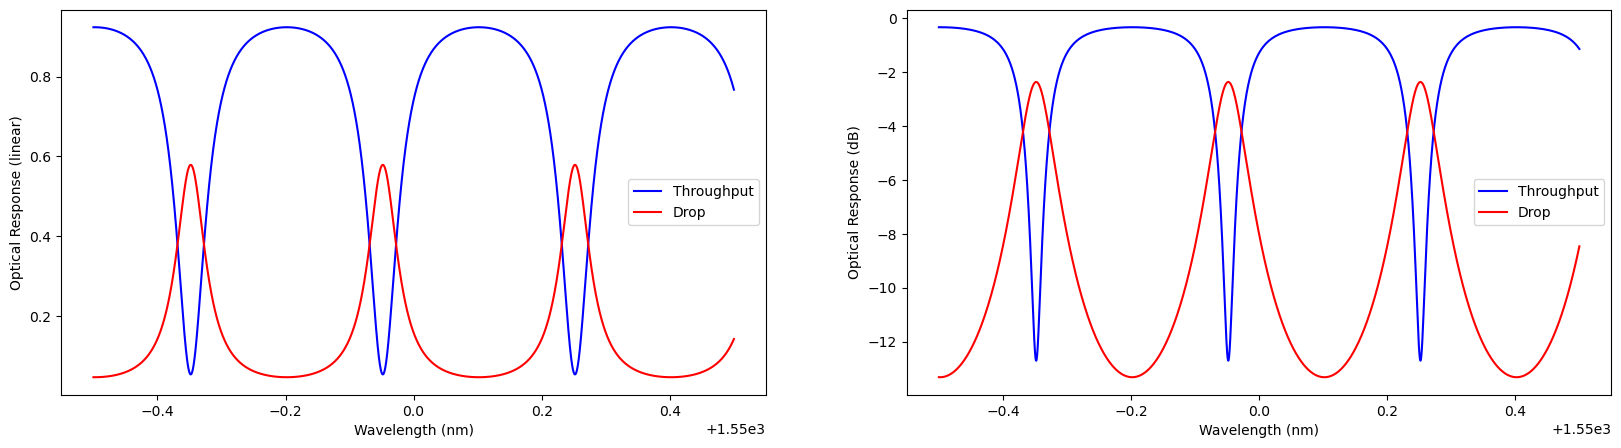

In [ ]:
# Ring Losses
loss_wg = 1 # Waveguide losses (dB/cm)
loss_ring_dB = loss_wg*L*1e2 # Total losses of the ring in dB
loss_mzi_dB = .5
loss_Np = loss_ring_dB/(20*np.log10(np.exp(1))) # Total losses of the ring in Nepers (Np)
loss_Np_mzi = loss_mzi_dB/(20*np.log10(np.exp(1))) # Total losses of the mzi in Nepers (Np)
alpha = loss_Np + 2 * loss_Np_mzi # Suma de alphas donde, al haber dos MZIs, se añade también a la suma
alpha = np.exp(-alpha)

# Coupling coefficients
t1 = 0.8
t2 = 0.8
k1 = np.sqrt(1-t1**2)
k2 = np.sqrt(1-t2**2)

# Angular phase
tau = (4 * np.pi**2 * neff * r) / wvl

# Output field
Et1 = -1j * np.exp(1j * delta) * (t1 - (alpha * np.exp(1j * (delta + delta)) * k1**2 * t1 * np.exp(1j * (tau + phi0))) / (1 - alpha * np.exp(1j * (delta + delta)) * t1 * t2 * np.exp(1j * (tau + phi0))))
Et4 = (-np.sqrt(alpha) * np.exp(1j * (delta + delta)) * k1 * k2 * np.exp(1j * (tau/2 + phi0))) / (1 - alpha * np.exp(1j * (delta + delta)) * t1 * t2 * np.exp(1j * (tau + phi0)))
Pt1 = abs(Et1)**2 # Transmission power in the output waveguide
Pt2 = abs(Et4)**2

# Plot figures
fig, axs = plt.subplots(1,2,figsize=(20, 5))
# Linear
axs[0].plot(wvl*1e9, Pt1, 'b', label='Throughput')
axs[0].plot(wvl*1e9, Pt2, 'r', label='Drop')
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
axs[0].legend()
# Logarithmic
axs[1].plot(wvl*1e9, 10*np.log10(Pt1), 'b', label='Throughput')
axs[1].plot(wvl*1e9, 10*np.log10(Pt2), 'r', label='Drop')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')
axs[1].legend()